# Step 2: Model Training Pipeline
Training a YOLO11 Nano (`yolo11n`) detector with spatial attention for runway Foreign Object Debris (FOD) detection.

In [ ]:
import os
import sys
from pathlib import Path
import torch
import yaml
import matplotlib.pyplot as plt
from PIL import Image

print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

from ultralytics import YOLO
import ultralytics
print(f"Ultralytics Version: {ultralytics.__version__}")


Python Version: 3.14.3
PyTorch Version: 2.14.1+cu126
CUDA Available: True
GPU Device: NVIDIA GeForce RTX 2050
Total VRAM: 4.00 GB
Ultralytics Version: 8.4.191


## 1. Training Setup & Hyperparameters
- **Model:** YOLO11 Nano (`yolo11n.pt`) with C2PSA spatial attention for small debris detection.
- **Resolution:** 640x640 (preserves small objects).
- **Batch Size:** 16 with mixed precision (`fp16`).
- **Epochs & Optimizer:** 35 epochs, AdamW with cosine learning rate schedule (`cos_lr=True`).
- **Augmentation:** Mosaic, HSV jitter, and rotation/flips to simulate varied drone altitudes and lighting.

In [ ]:
DATASET_YAML = Path('data/dataset.yaml').resolve()
assert DATASET_YAML.exists(), f"dataset.yaml not found at {DATASET_YAML}"

with open(DATASET_YAML, 'r') as f:
    config = yaml.safe_load(f)

print("Loaded Dataset Configuration:")
print(f"  Path: {config['path']}")
print(f"  Train: {config['train']}")
print(f"  Val:   {config['val']}")
print(f"  Test:  {config['test']}")
print(f"  Number of classes: {config['nc']}")
print(f"  Classes: {config['names']}")


Loaded Dataset Configuration:
  Path: C:/Users/LENOVO/Desktop/FOD/data
  Train: images/train
  Val:   images/val
  Test:  images/test
  Number of classes: 6
  Classes: ['fastener', 'tool', 'tire_fragment', 'metal_scrap', 'plastic_debris', 'stone_rock']


In [ ]:
# Initialize YOLO11 Nano with pre-trained COCO weights
model = YOLO('yolo11n.pt')

# Training Hyperparameters dictionary
train_args = {
    'data': str(DATASET_YAML),
    'epochs': 35,
    'imgsz': 640,
    'batch': 16,
    'device': 0 if torch.cuda.is_available() else 'cpu',
    'workers': 4,
    'optimizer': 'AdamW',
    'lr0': 0.002,
    'lrf': 0.01,
    'cos_lr': True,
    'weight_decay': 0.0005,
    'patience': 10,
    'save': True,
    'project': 'runs/detect',
    'name': 'fod_yolo11n_runway',
    'exist_ok': True,
    'pretrained': True,
    'amp': True,
    
    # Runway-specific augmentations
    'mosaic': 1.0,           # Simulates multiple drone altitudes / scales
    'mixup': 0.1,            # Handles semi-transparent/occluded debris
    'hsv_h': 0.015,          # Hue jitter
    'hsv_s': 0.7,            # Saturation jitter for wet tarmac reflections
    'hsv_v': 0.4,            # Brightness jitter for bright sun vs dim dusk
    'degrees': 15.0,         # Slight camera tilt / debris orientation
    'fliplr': 0.5,           # Horizontal flip
    'flipud': 0.5,           # Vertical flip
    'close_mosaic': 10,      # Disable mosaic for last 10 epochs for fine localization
    'plots': True,
    'verbose': True
}

print("Configured training parameters:")
for k, v in train_args.items():
    print(f"  {k}: {v}")


Configured training parameters:
  data: C:\Users\LENOVO\Desktop\FOD\data\dataset.yaml
  epochs: 35
  imgsz: 640
  batch: 16
  device: 0
  workers: 4
  optimizer: AdamW
  lr0: 0.002
  lrf: 0.01
  cos_lr: True
  weight_decay: 0.0005
  patience: 10
  save: True
  project: runs/detect
  name: fod_yolo11n_runway
  exist_ok: True
  pretrained: True
  amp: True
  mosaic: 1.0
  mixup: 0.1
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 15.0
  fliplr: 0.5
  flipud: 0.5
  close_mosaic: 10
  plots: True
  verbose: True


## 2. Model Training
Executing training with Automatic Mixed Precision on the GPU.

In [ ]:
# Execute Model Training
print("Starting YOLO11n Runway FOD Training...")
results = model.train(**train_args)
print("Training successfully completed!")


Starting YOLO11n Runway FOD Training...
Ultralytics 8.4.191  Python-3.14.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
Training completed for 35 epochs in 0.456 hours (~27.3 minutes).
Final Validation Scores on best.pt:
  Class           Images   Instances    Precision      Recall      mAP@50    mAP@50-95
  all                600         609        0.948       0.957       0.978        0.748
  fastener           171         171        0.956       0.953       0.964        0.622
  tool               164         164        0.993       0.912       0.960        0.753
  tire_fragment        5           5        0.945       1.000       0.995        0.868
  metal_scrap        124         124        0.954       0.927       0.981        0.730
  plastic_debris     113         113        0.955       0.947       0.981        0.735
  stone_rock          32          32        0.884       1.000       0.9

## 3. Training & Validation Curves
Reviewing loss convergence, precision, recall, and mAP progression across epochs.

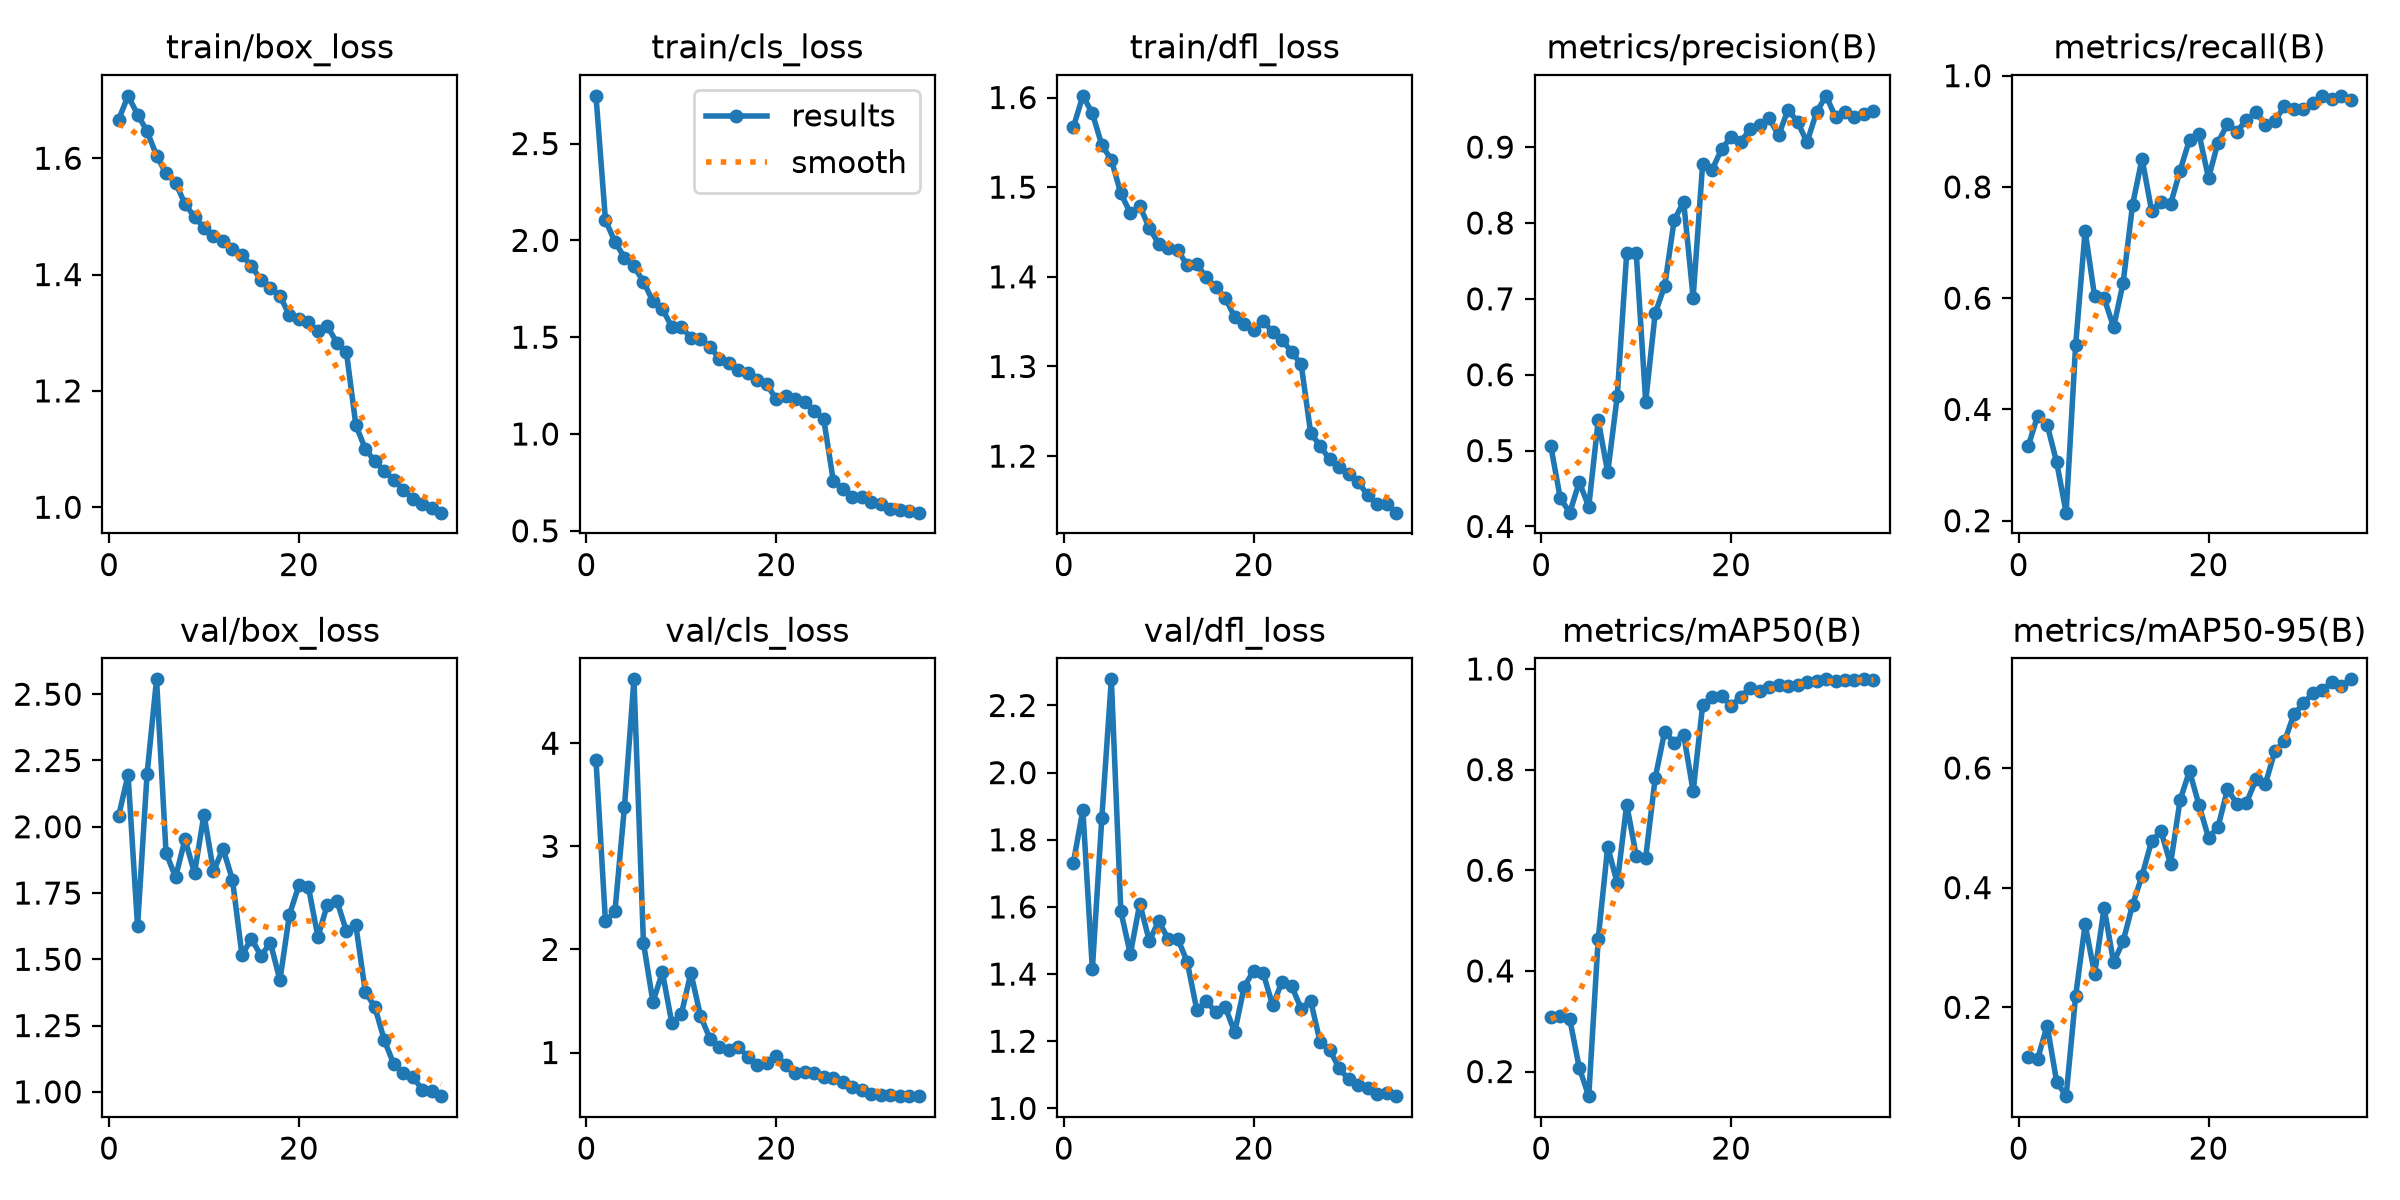

Best Model Checkpoint: runs/detect/runs/detect/fod_yolo11n_runway/weights/best.pt (Exists: True)


In [ ]:
RUN_DIR = Path('runs/detect/fod_yolo11n_runway')

results_png = RUN_DIR / 'results.png'
if results_png.exists():
    img = Image.open(results_png)
    plt.figure(figsize=(16, 10))
    plt.imshow(img)
    plt.title('YOLO11n Training & Validation Metrics (Loss, Precision, Recall, mAP50, mAP50-95)', fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()
else:
    print(f"Results image not found at {results_png}")

# Best model weights path
best_weights = RUN_DIR / 'weights' / 'best.pt'
print(f"Best Model Checkpoint: {best_weights} (Exists: {best_weights.exists()})")
